# Lab 04-06 · Magnetic Fields and Forces

Companion to chapter [04-06](../../chapters/04-06-magnetic-fields-and-forces.md). Handout: [README.md](README.md).

Cells marked **🔮 Predict** ask for a prediction *before* running. Nothing here is random.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
e, me, mp = 1.602176634e-19, 9.1093837139e-31, 1.67262192595e-27
mu0 = 1.25663706127e-6

## Part 1 — Charges in fields

Integrate $m\,d\vec v/dt = q(\vec E + \vec v\times\vec B)$. First an electron at $10^6$ m/s in 0.1 T (Example 04-06.1); then a proton released from rest in crossed fields, $\vec E$ = 1 kV/m along $x$ and $\vec B$ = 0.1 T along $z$.

**🔮 Predict:** in crossed fields, which way does the proton drift on average: along $\vec E$, along $\vec B$, or perpendicular to both? How fast?

electron: orbit diameter 113.71 um (2r = 113.71 um); returns to start after one period: 0.000 nm off
proton in crossed fields: average drift along y = -10000.0 m/s (E/B = 10000 m/s); net motion along x after 5 periods: 0.000 um


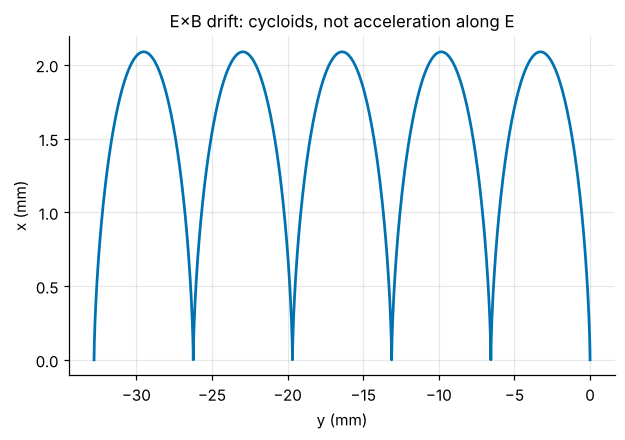

In [2]:
def lorentz(q, m, E, B):
    E, B = np.asarray(E, float), np.asarray(B, float)
    return lambda t, s: np.concatenate([s[3:], q / m * (E + np.cross(s[3:], B))])
T_e = 2 * math.pi * me / (e * 0.1)
sol = solve_ivp(lorentz(-e, me, [0, 0, 0], [0, 0, 0.1]), (0, T_e), [0, 0, 0, 1e6, 0, 0], rtol=1e-10, atol=1e-14, max_step=T_e / 400)
x, y = sol.y[0], sol.y[1]
print(f"electron: orbit diameter {(y.max() - y.min())*1e6:.2f} um (2r = {2*me*1e6/(e*0.1)*1e6:.2f} um); returns to start after one period: {np.hypot(x[-1], y[-1])*1e9:.3f} nm off")
T_p = 2 * math.pi * mp / (e * 0.1)
sol2 = solve_ivp(lorentz(e, mp, [1e3, 0, 0], [0, 0, 0.1]), (0, 5 * T_p), [0, 0, 0, 0, 0, 0], rtol=1e-10, atol=1e-12, max_step=T_p / 200)
drift = (sol2.y[1, -1] - sol2.y[1, 0]) / (5 * T_p)
print(f"proton in crossed fields: average drift along y = {drift:.1f} m/s (E/B = {1e3/0.1:.0f} m/s); net motion along x after 5 periods: {sol2.y[0, -1]*1e6:.3f} um")
plt.plot(sol2.y[1] * 1e3, sol2.y[0] * 1e3); plt.xlabel("y (mm)"); plt.ylabel("x (mm)"); plt.title("E×B drift: cycloids, not acceleration along E"); plt.show()

The proton does *not* accelerate along $\vec E$: it traces cycloids and drifts along $\vec E\times\vec B$ (here $-y$) at $E/B$ = 10 km/s, whatever its charge or mass. This **E×B drift** confines plasmas in etch and sputtering tools (magnetrons) and in fusion devices.

## Part 2 — Biot–Savart by computer

Chop a loop into straight segments, sum $d\vec B = (\mu_0I/4\pi)\,d\vec l\times\hat r/r^2$, and build a **Helmholtz pair**: two coaxial coils of radius $R$ spaced $R$ apart, carrying the same current.

**🔮 Predict:** how uniform is the field near the midpoint, compared with a single coil?

Helmholtz center: 0.1798 mT  (formula (4/5)^1.5 mu0 N I / R = 0.1798 mT)
change 1 cm from center: Helmholtz 0.176 %, single coil 5.71 %


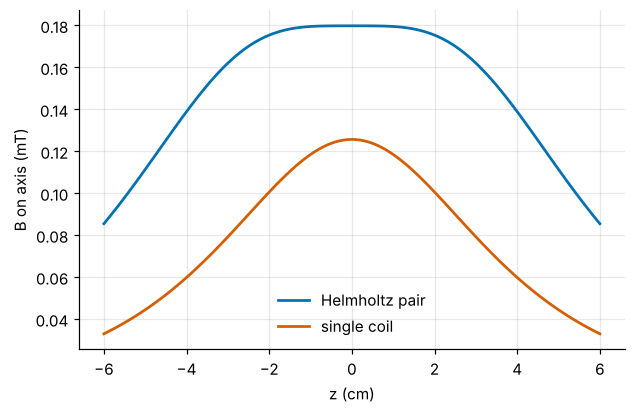

In [3]:
def loop_field(point, R, z0, I, n=720):
    phi = np.linspace(0, 2 * math.pi, n + 1)
    pts = np.stack([R * np.cos(phi), R * np.sin(phi), np.full_like(phi, z0)], axis=1)
    mid, dl = 0.5 * (pts[1:] + pts[:-1]), np.diff(pts, axis=0)
    rvec = np.asarray(point, float) - mid
    r3 = np.linalg.norm(rvec, axis=1) ** 3
    return mu0 * I / (4 * math.pi) * (np.cross(dl, rvec) / r3[:, None]).sum(axis=0)
R, N, I = 0.05, 10, 1.0
helm = lambda z: N * (loop_field([0, 0, z], R, -R / 2, I) + loop_field([0, 0, z], R, R / 2, I))[2]
single = lambda z: N * loop_field([0, 0, z], R, 0, I)[2]
print(f"Helmholtz center: {helm(0)*1e3:.4f} mT  (formula (4/5)^1.5 mu0 N I / R = {(0.8)**1.5*mu0*N*I/R*1e3:.4f} mT)")
print(f"change 1 cm from center: Helmholtz {(1 - helm(0.01)/helm(0))*100:.3f} %, single coil {(1 - single(0.01)/single(0))*100:.2f} %")
zz = np.linspace(-0.06, 0.06, 121)
plt.plot(zz * 100, [helm(z) * 1e3 for z in zz], label="Helmholtz pair")
plt.plot(zz * 100, [single(z) * 1e3 for z in zz], label="single coil")
plt.xlabel("z (cm)"); plt.ylabel("B on axis (mT)"); plt.legend(); plt.show()

With spacing equal to the radius, the second derivative of the field cancels at the midpoint, leaving a field flat to about 0.2% over ±1 cm (a fifth of the radius), against almost 6% for a single coil: the standard way to make a known, uniform field for calibrating magnetic sensors.

## Part 3 — Ampère's law checked numerically

Compute the Biot–Savart field of a very long straight wire (20 m, 1 A) and integrate $\vec B\cdot d\vec l$ around circles that do and do not enclose it.

**🔮 Predict:** the loop integral divided by $\mu_0I$, for a circle around the wire and for one beside it.

In [4]:
def wire_field(p, L=20.0, I=1.0, n=40001):
    zs = np.linspace(-L / 2, L / 2, n)
    mid, dz = 0.5 * (zs[1:] + zs[:-1]), np.diff(zs)
    rvec = np.asarray(p, float)[None, :] - np.stack([np.zeros_like(mid), np.zeros_like(mid), mid], axis=1)
    dl = np.stack([np.zeros_like(dz), np.zeros_like(dz), dz], axis=1)
    r3 = np.linalg.norm(rvec, axis=1) ** 3
    return mu0 * I / (4 * math.pi) * (np.cross(dl, rvec) / r3[:, None]).sum(axis=0)
def loop_integral(cx, cy, rad, n=400):
    th = np.linspace(0, 2 * math.pi, n, endpoint=False)
    total = 0.0
    for t in th:
        p = [cx + rad * math.cos(t), cy + rad * math.sin(t), 0.0]
        dl = np.array([-math.sin(t), math.cos(t), 0.0]) * rad * 2 * math.pi / n
        total += wire_field(p) @ dl
    return total / mu0
print(f"circle of radius 1 cm around the wire: {loop_integral(0, 0, 0.01):.5f} (units of mu0 I)")
print(f"circle of radius 1 cm centered 3 cm away: {loop_integral(0.03, 0, 0.01):.2e}")

circle of radius 1 cm around the wire: 1.00000 (units of mu0 I)


circle of radius 1 cm centered 3 cm away: -5.00e-07


Around the wire the integral is $\mu_0I$ (to the precision of the 20 m wire's finite length); a loop that does not enclose the current gives zero, even though $\vec B$ is nonzero all along it.

## Part 4 — Hall sensors

**🔮 Predict:** by how much does the Hall voltage change if you halve the plate thickness? Double the doping?

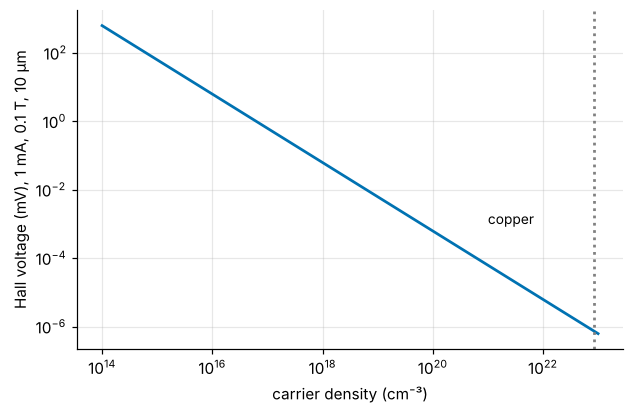

silicon at 1e16 cm^-3: 6.242 mV


In [5]:
I, B, t = 1e-3, 0.1, 10e-6
n_cm3 = np.logspace(14, 23, 100)
VH = I * B / (n_cm3 * 1e6 * e * t)
plt.loglog(n_cm3, VH * 1e3); plt.axvline(8.49e22, ls=":", color="0.5"); plt.text(1e21, 1e-3, "copper", fontsize=9)
plt.xlabel("carrier density (cm⁻³)"); plt.ylabel("Hall voltage (mV), 1 mA, 0.1 T, 10 µm"); plt.show()
print(f"silicon at 1e16 cm^-3: {I*B/(1e22*e*t)*1e3:.3f} mV")

## Part 5 — Gapping a ferrite core

Saturation current of the 5 cm, 20-turn, $\mu_r$ = 2000 core of Example 04-06.8 against air-gap length, at 25 and 100 °C.

**🔮 Predict:** the saturation current at 100 °C with a 1 mm gap.

I_sat at 100 C with a 1 mm gap: 15.91 A


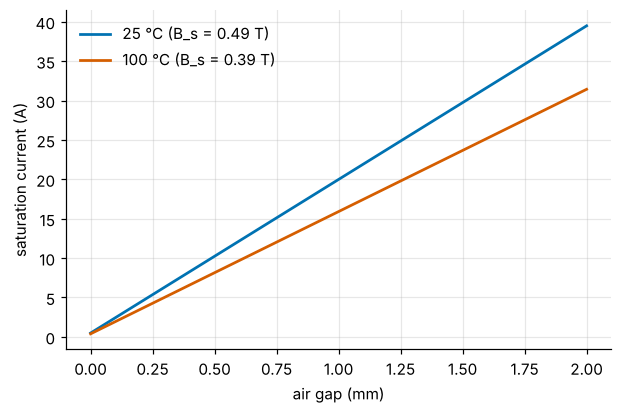

In [6]:
l, mur, Nt = 0.05, 2000, 20
g = np.linspace(0, 2e-3, 200)
for Bs, T in ((0.49, 25), (0.39, 100)):
    plt.plot(g * 1e3, Bs * (l / mur + g) / (mu0 * Nt), label=f"{T} °C (B_s = {Bs} T)")
print(f"I_sat at 100 C with a 1 mm gap: {0.39*(l/mur + 1e-3)/(mu0*Nt):.2f} A")
plt.xlabel("air gap (mm)"); plt.ylabel("saturation current (A)"); plt.legend(); plt.show()

The saturation current rises almost linearly with the gap once the gap dominates the magnetic path; the price is inductance per turn, which falls by the same factor (04-07).

## Your turn

1. In Part 1, give the proton an initial velocity of exactly $E/B$ along $-y$. What happens, and why is this the velocity selector?
2. In Part 2, change the coil spacing to $0.8R$ and $1.2R$. Which way does the field profile bow?